# **Tik-Tok Analysis using NLP**

### Objective

* Sentiment Analysis on TikTok Reviews: Extract key features users like or complain about using sentiment-labeled text analysis.

* User Segmentation (Clustering): Group TikTok users into "Creators" vs. "Casual Viewers" using unsupervised learning.

### PART 1: Sentiment Analysis on TikTok Reviews

In this section, we analyze user feedback from TikTok app reviews to uncover what users **like**, what **issues** they face, and what **features** they wish to see. We use Natural Language Processing (NLP) and sentiment analysis to quantify user opinions.

### Dataset Overview

The dataset contains app reviews with the following columns:

- `review_id`: Unique identifier for each review
- `review_text`: The actual text content of the review
- `upvotes`: Number of helpful votes the review received
- `app_version`: TikTok version when review was posted
- `posted_date`: Date of submission

Our primary focus is on analyzing `review_text` to extract sentiments and keyword trends.

### Sentiment Analysis Workflow

1. **Text Cleaning**:
   - Remove punctuation, emojis, links, and stopwords to clean the review text.

2. **Sentiment Labeling**:
   - Use the **VADER sentiment analyzer** to classify each review as:
     - **Positive**
     - **Neutral**
     - **Negative**

3. **Sentiment Distribution Visualization**:
   - Plot the overall sentiment breakdown to understand public opinion.

4. **Keyword Exploration**:
   - Generate **word clouds** for positive and negative reviews to extract frequently mentioned themes, features, or problems.

5. **Export Cleaned Data**:
   - Save the sentiment-tagged reviews to a CSV file for further use in business reports or dashboards.

📌 This analysis gives insight into **what users appreciate** about TikTok and **what pain points** need addressing, supporting **data-driven app improvements** and **customer satisfaction strategies**.




### PART 1: Sentiment Analysis on TikTok Reviews Implementation

#### 1. Setup & Preprocessing

In [2]:
!pip install wordcloud

In [4]:
pip install vaderSentiment matplotlib seaborn nltk scikit-learn


In [4]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string
import nltk
from wordcloud import WordCloud
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import warnings
warnings.filterwarnings("ignore")

nltk.download('stopwords')
stop_words = set(stopwords.words('english'))


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\malip\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


#### Load the Reviews Dataset



In [5]:
# Load dataset
reviews_df = pd.read_csv("C:\\Users\\malip\\Desktop\\project\\tiktok_app_reviews.csv") 
print(reviews_df.head())

                                           review_id  \
0  gp:AOqpTOGSsGv5rOA79ttW2LE0FeMYvkdUuXRMTfbyMk0...   
1  gp:AOqpTOEDQ9__FJihY_0V4iwqy4P2OK8tGVR1tFBixYb...   
2  gp:AOqpTOEGEfr8TL0iKTlpbTDeM8P7HywlMmP9CkHMoaT...   
3  gp:AOqpTOGZBDl9dpghmb43Mx1tnlWCOjNXyuVn5Mxf49c...   
4  gp:AOqpTOFioH3wud_JnC4aPCG4p7s5DEEN2yZAWNXdRJj...   

                                         review_text  upvotes app_version  \
0  It is an excellent solution to finding videos ...      402      21.2.5   
1  Great app works really well so many features s...       67      21.2.5   
2  I down loaded app but didnt work . i love this...       24      21.2.5   
3  IT A GREAT APP AND FUN TO USE! HOWEVER ARBITRA...       18      21.2.5   
4  Currently it's working good for me except a fe...      232     21.1.41   

           posted_date  
0  2021-09-20 07:50:23  
1  2021-09-19 23:10:47  
2  2021-09-19 08:59:34  
3  2021-09-19 16:34:43  
4  2021-09-14 06:35:02  



Above is a preview of the first few rows in the **TikTok app reviews dataset**. Each row represents a user review submitted to the app store:

| Column Name         | Description                                                                 |
|---------------------|-----------------------------------------------------------------------------|
| `review_id`         | Unique identifier for each review (from Google Play)                        |
| `review_text`       | Text content of the user’s review                                           |
| `upvotes`           | Number of users who marked the review as helpful                           |
| `app_version`       | Version of the TikTok app when the review was submitted                    |
| `posted_date`       | Date and time when the review was posted                                   |

This dataset forms the foundation of our sentiment analysis, where we extract and analyze the **opinions, issues, and feedback** shared by TikTok users.



#### Clean the Review Texts

In [6]:
#Text Cleaning Function
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'\[.*?\]', '', text)
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>+', '', text)
    text = re.sub(r'[%s]' % re.escape(string.punctuation), '', text)
    text = re.sub(r'\n', '', text)
    text = re.sub(r'\w*\d\w*', '', text)
    text = ' '.join(word for word in text.split() if word not in stop_words)
    return text


In [7]:
# Check all column names
print(reviews_df.columns)

Index(['review_id', 'review_text', 'upvotes', 'app_version', 'posted_date'], dtype='object')


In [8]:
# Apply Cleaning
reviews_df['cleaned_review'] = reviews_df['review_text'].apply(clean_text)
reviews_df.head()


,review_id,review_text,upvotes,app_version,posted_date,cleaned_review
0,gp:AOqpTOGSsGv5rOA79ttW2LE0FeMYvkdUuXRMTfbyMk0...,It is an excellent solution to finding videos ...,402,21.2.5,2021-09-20 07:50:23,excellent solution finding videos following pe...
1,gp:AOqpTOEDQ9__FJihY_0V4iwqy4P2OK8tGVR1tFBixYb...,Great app works really well so many features s...,67,21.2.5,2021-09-19 23:10:47,great app works really well many features many...
2,gp:AOqpTOEGEfr8TL0iKTlpbTDeM8P7HywlMmP9CkHMoaT...,I down loaded app but didnt work . i love this...,24,21.2.5,2021-09-19 08:59:34,loaded app didnt work love app could maybe fix...
3,gp:AOqpTOGZBDl9dpghmb43Mx1tnlWCOjNXyuVn5Mxf49c...,IT A GREAT APP AND FUN TO USE! HOWEVER ARBITRA...,18,21.2.5,2021-09-19 16:34:43,great app fun use however arbitrary algorithms...
4,gp:AOqpTOFioH3wud_JnC4aPCG4p7s5DEEN2yZAWNXdRJj...,Currently it's working good for me except a fe...,232,21.1.41,2021-09-14 06:35:02,currently working good except clips video work...


The table below shows the TikTok reviews after preprocessing. A new column called **`cleaned_review`** has been added by applying text normalization techniques to `review_text`.

#### What Was Done in Cleaning:
- Converted text to lowercase
- Removed punctuation and numbers
- Removed stopwords (e.g., "the", "and", "is")
- Removed URLs and special characters

| Column Name      | Description                                                         |
|------------------|----------------------------------------------------------------------|
| `review_text`    | Original user-submitted app review                                   |
| `cleaned_review` | Processed version of the text — cleaner and ready for sentiment analysis |

This cleaned text is now suitable for input into **sentiment analysis models**, ensuring better accuracy by removing noise from the data.



#### Sentiment Labeling with VADER

In [7]:
# Sentiment Analysis
sia = SentimentIntensityAnalyzer()

def get_sentiment(text):
    score = sia.polarity_scores(text)['compound']
    if score >= 0.05:
        return 'positive'
    elif score <= -0.05:
        return 'negative'
    else:
        return 'neutral'

reviews_df['sentiment'] = reviews_df['cleaned_review'].apply(get_sentiment)
reviews_df[['review_text', 'sentiment']].head()


,review_text,sentiment
0,It is an excellent solution to finding videos ...,positive
1,Great app works really well so many features s...,positive
2,I down loaded app but didnt work . i love this...,positive
3,IT A GREAT APP AND FUN TO USE! HOWEVER ARBITRA...,positive
4,Currently it's working good for me except a fe...,neutral


#### Sentiment Analysis Results

The table below displays TikTok user reviews alongside their predicted **sentiment labels**, generated using the **VADER sentiment analyzer**.

| Column Name   | Description                                                                 |
|---------------|-----------------------------------------------------------------------------|
| `review_text` | The original text of the user-submitted review                              |
| `sentiment`   | Predicted sentiment category: `positive`, `neutral`, or `negative`         |

We used **VADER (Valence Aware Dictionary and sEntiment Reasoner)**, a rule-based sentiment analysis tool designed for social media text. It calculates a compound sentiment score and classifies it as:

- `Positive` if score ≥ 0.05  
- `Negative` if score ≤ -0.05  
- `Neutral` otherwise

This allows us to quantify user feedback and analyze what users **enjoy** and what issues they may be **complaining** about.

### Visualize Sentiment Distribution

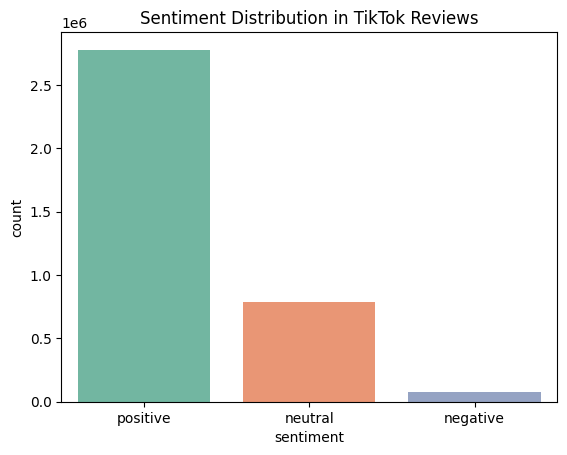

In [9]:
# Plot Sentiment Counts
sns.countplot(data=reviews_df, x='sentiment', palette='Set2')
plt.title('Sentiment Distribution in TikTok Reviews')
plt.show()


The bar chart above shows the **overall sentiment breakdown** of user reviews after applying sentiment analysis using the VADER model.

- **Positive** reviews dominate the dataset, indicating a largely satisfied user base.
- **Neutral** reviews are moderately common — likely including generic feedback or mixed opinions.
- **Negative** reviews form the smallest segment, which may still provide valuable insights into **user pain points or bugs**.

This high-level visualization helps stakeholders quickly assess **user satisfaction trends**, guiding further investigation into **positive features** and **common complaints**.


### Word Clouds for Positive & Negative Reviews

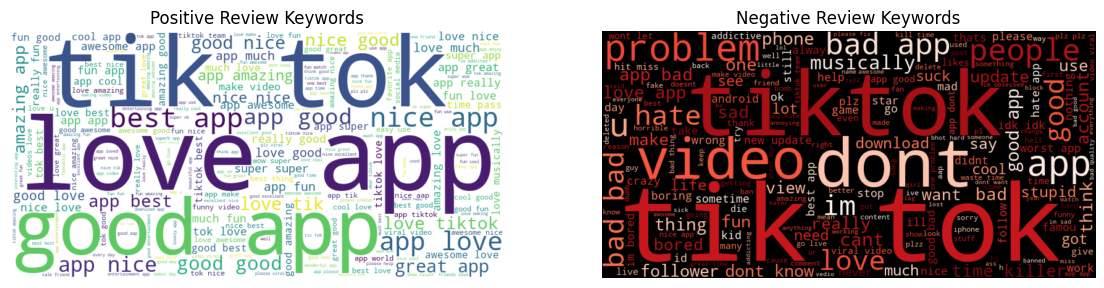

In [8]:
# Generate Word Clouds
positive_reviews = ' '.join(reviews_df[reviews_df['sentiment']=='positive']['cleaned_review'])
negative_reviews = ' '.join(reviews_df[reviews_df['sentiment']=='negative']['cleaned_review'])

wordcloud_pos = WordCloud(width=800, height=400, background_color='white').generate(positive_reviews)
wordcloud_neg = WordCloud(width=800, height=400, background_color='black', colormap='Reds').generate(negative_reviews)

plt.figure(figsize=(14,6))
plt.subplot(1,2,1)
plt.imshow(wordcloud_pos, interpolation='bilinear')
plt.axis('off')
plt.title('Positive Review Keywords')

plt.subplot(1,2,2)
plt.imshow(wordcloud_neg, interpolation='bilinear')
plt.axis('off')
plt.title('Negative Review Keywords')
plt.show()


The visualizations above display the most frequently occurring words in:

- **Left:** Reviews classified as **Positive**
- **Right:** Reviews classified as **Negative**

#### Positive Reviews:
- Dominated by words like **“love”**, **“good”**, **“awesome”**, **“fun”**, and **“nice”**.
- Indicates users appreciate the **entertainment value**, **user experience**, and overall **satisfaction** with the app.

#### Negative Reviews:
- Common words include **“problem”**, **“don’t”**, **“bad”**, **“update”**, and **“hate”**.
- Suggests frustration with **app performance**, **bugs**, **unwanted updates**, or **content issues**.

These word clouds help businesses understand both **what users value most** and **which issues they frequently report**, guiding **feature improvements** and **customer support priorities**.


### Save Sentiment Output

In [10]:
#Save the Processed File
reviews_df.to_csv("processed_tiktok_reviews.csv", index=False)

---

## PART 2: Clustering TikTok Users(Creators vs. Viewers)

In this section, we segment TikTok users based on activity and engagement metrics to distinguish **Content Creators** from **Casual Viewers** using unsupervised learning.


### Dataset Overview

The dataset includes user metadata such as:

- `followers`: Total followers a user has
- `following`: Number of accounts the user follows
- `likes`: Total likes received
- `videos_count`: Number of videos posted
- `awg_engagement_rate`: Average engagement rate
- `like_engagement_rate`: Engagement based on likes
- `comment_engagement_rate`: Engagement based on comments

These features can reveal how active or influential a user is on TikTok.

### Clustering Workflow

1. **Feature Selection & Cleaning**:
   - We select relevant numerical features and drop rows with missing values.

2. **Feature Scaling**:
   - Normalize the features using `StandardScaler` to ensure all inputs contribute equally.

3. **Clustering (KMeans)**:
   - Apply the KMeans algorithm to group users based on similarity.
   - Use `n_clusters=2` to identify two groups: likely **Creators** and **Viewers**.

4. **PCA Visualization**:
   - Use Principal Component Analysis to project users into 2D space and visualize clusters.

5. **Label Clusters**:
   - Analyze which cluster has higher average `followers` and `videos_count`, and label them as **Creators**.

6. **Save Results**:
   - Store clustered user data with labels into a CSV file for business use and marketing strategies.


📌 This analysis helps businesses identify influencers (creators) and casual users, enabling **targeted campaigns, collaborations, and promotions**.




### Load and Inspect the User Dataset

In [9]:
# Load User Dataset
users_df = pd.read_csv("C:\\Users\\malip\\Desktop\\project\\TikTok profiles dataset (Public web data).csv")  
users_df.head()


,timestamp,account_id,nickname,biography,awg_engagement_rate,comment_engagement_rate,like_engagement_rate,bio_link,is_verified,followers,following,likes,videos_count,create_time,id,top_videos,url,profile_pic_url
0,2023-08-01,a.r.m.y664,❤️❤️❤️,nazywam się Basia 🇵🇱+🇺🇸 moja mama jest z USA 🖤...,0.049630,0.004473,0.045157,NaN,False,1755,1443,1586,20,NaN,6794435137251820550,https://www.tiktok.com/@a.r.m.y664/video/68236...,https://www.tiktok.com/@a.r.m.y664,https://p77-sign-va.tiktokcdn.com/musically-ma...
1,2023-08-01,a2_9r,ايمن الفستقي🍺🥂🥃,حسابي الاصلي تيكتككك(_8_ytp_,0.059322,0.004358,0.054964,NaN,False,354,1422,3843,225,NaN,7019722709156430853,https://www.tiktok.com/@a2_9r/video/7218348887...,https://www.tiktok.com/@a2_9r,https://p16-sign-va.tiktokcdn.com/tos-maliva-a...
2,2023-07-30,ti.po.check,All,Активный пользователь ТикТока 🌝\nМеня зовут BD...,0.001399,0.000058,0.001341,NaN,False,1960,243,24000,228,NaN,6826677567140873222,https://www.tiktok.com/@ti.po.check/video/6984...,https://www.tiktok.com/@ti.po.check,https://p58-sign-sg.tiktokcdn.com/aweme/720x72...
3,2023-08-06,nutrifersanort,L.N Fernanda Sánchez,"Nutrióloga, educadora en diabetes.",0.469767,0.004651,0.465116,NaN,False,43,41,100,5,NaN,6809397670235407365,https://www.tiktok.com/@nutrifersanort/video/7...,https://www.tiktok.com/@nutrifersanort,https://p16-sign-va.tiktokcdn.com/tos-maliva-a...
4,2023-07-25,bhgdee,D💲,Ig-bhg.dee📸\nSc-dannieo2099 👻\nFb- frank matth...,0.122283,0.008152,0.114130,NaN,False,276,2262,126,4,NaN,6810526136080483334,https://www.tiktok.com/@bhgdee/video/719722663...,https://www.tiktok.com/@bhgdee,https://p16-sign.tiktokcdn-us.com/tos-useast5-...


The table below shows a few rows from the TikTok user profile dataset. Each row represents an individual TikTok account, with metadata on activity, engagement, and content.

| Column Name                | Description                                                                 |
|----------------------------|-----------------------------------------------------------------------------|
| `timestamp`               | Date when this user profile was scraped or updated                          |
| `account_id`, `nickname`  | TikTok account name and display nickname                                     |
| `biography`               | User bio (self-description)                                                  |
| `followers`, `following`  | Number of followers and accounts followed by the user                        |
| `likes`                   | Total number of likes received on content                                    |
| `videos_count`            | Total number of videos posted by the user                                    |
| `awg_engagement_rate`     | Average engagement rate per video                                            |
| `like_engagement_rate`    | Percentage of likes relative to followers                                    |
| `comment_engagement_rate` | Percentage of comments relative to followers                                 |
| `is_verified`             | Boolean flag indicating whether the account is verified                      |
| `bio_link`, `url`         | Links to user's bio, profile, or TikTok content                              |
| `top_videos`              | URL to one of the user's top videos                                          |
| `profile_pic_url`         | Link to the user's profile picture                                           |

This dataset provides the foundation for **user segmentation via clustering**, helping us distinguish between **creators** (high activity and influence) and **casual viewers**.


### Preprocess and Normalize Features

In [14]:
print(users_df.columns)

Index(['timestamp', 'account_id', 'nickname', 'biography',
       'awg_engagement_rate', 'comment_engagement_rate',
       'like_engagement_rate', 'bio_link', 'is_verified', 'followers',
       'following', 'likes', 'videos_count', 'create_time', 'id', 'top_videos',
       'url', 'profile_pic_url'],
      dtype='object')


In [10]:
# Select & Normalize Features
from sklearn.preprocessing import StandardScaler

# Select relevant features for clustering
features = ['followers', 'following', 'likes', 'videos_count', 
            'awg_engagement_rate', 'like_engagement_rate', 'comment_engagement_rate']

# Drop rows with missing values in selected features
users_df = users_df.dropna(subset=features)

# Extract the feature data
X = users_df[features]

# Normalize the feature data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)



To prepare the TikTok user data for clustering, we select relevant numerical features that represent a user's **engagement level**, **content activity**, and **influence** on the platform.

#### Features Used:
- `followers`: Number of followers
- `following`: Number of accounts the user follows
- `likes`: Total likes received on content
- `videos_count`: Total number of videos posted
- `awg_engagement_rate`: Average engagement per post
- `like_engagement_rate`: Proportion of likes received
- `comment_engagement_rate`: Proportion of comments received

#### Data Preparation Steps:
1. **Drop missing values** from selected features to avoid distortion in clustering.
2. **Normalize features** using `StandardScaler` to bring all values to the same scale (mean = 0, std = 1), ensuring no single feature dominates the clustering process.

This scaled feature matrix (`X_scaled`) is now ready to be used in clustering algorithm **K-Means**.

### KMeans Clustering

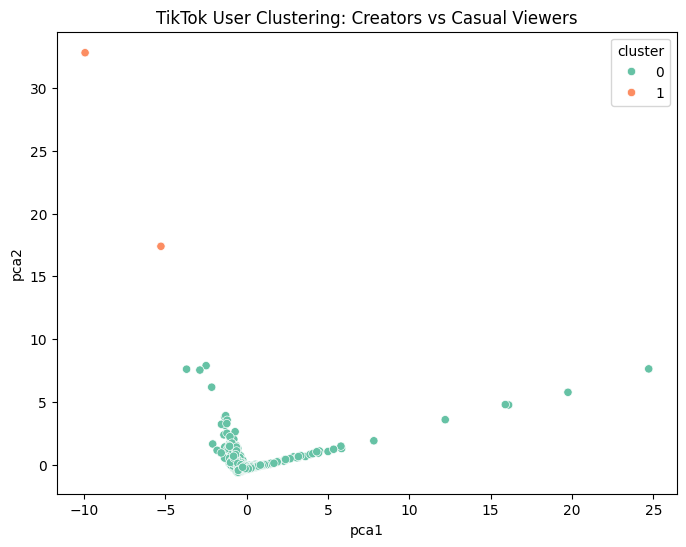

In [11]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# Apply KMeans
kmeans = KMeans(n_clusters=2, random_state=42)
users_df['cluster'] = kmeans.fit_predict(X_scaled)

# PCA for 2D Visualization
pca = PCA(n_components=2)
components = pca.fit_transform(X_scaled)
users_df['pca1'] = components[:, 0]
users_df['pca2'] = components[:, 1]

# Visualize Clusters
plt.figure(figsize=(8,6))
sns.scatterplot(data=users_df, x='pca1', y='pca2', hue='cluster', palette='Set2')
plt.title("TikTok User Clustering: Creators vs Casual Viewers")
plt.show()


The scatter plot above visualizes TikTok users grouped into **two clusters** using the **KMeans algorithm**, based on normalized behavioral features like followers, engagement rate, likes, and videos count.
- We used **PCA (Principal Component Analysis)** to reduce the feature space to **2D** for visual clarity.
- Each point represents a user, and their position is determined by the most important patterns in their behavior.

#### Cluster Meaning:
| Cluster | Interpretation      | Behavior Traits                                     |
|---------|---------------------|-----------------------------------------------------|
| `0`     | **Casual Viewers**  | Lower activity, engagement, and content creation    |
| `1`     | **Content Creators**| Higher followers, more videos, higher engagement    |

**Note:** These labels are assigned heuristically by comparing average feature values across clusters. Creators usually have more videos and followers.

This type of clustering helps businesses:
- Identify high-value influencers for partnerships.
- Tailor experiences or recommendations to user segments.
- Design marketing strategies for creators vs. viewers.

### Assign Labels Based on Heuristics

In [19]:
# Heuristic: Creators usually have more followers & videos
cluster_stats = users_df.groupby('cluster')[['followers', 'videos_count']].mean()
creator_cluster = cluster_stats['followers'].idxmax()

users_df['user_type'] = users_df['cluster'].apply(
    lambda x: 'Creator' if x == creator_cluster else 'Viewer'
)

# Preview results
users_df[['nickname', 'followers', 'videos_count', 'user_type']].head()


,nickname,followers,videos_count,user_type
0,❤️❤️❤️,1755,20,Viewer
1,ايمن الفستقي🍺🥂🥃,354,225,Viewer
2,All,1960,228,Viewer
3,L.N Fernanda Sánchez,43,5,Viewer
4,D💲,276,4,Viewer


The table below shows the final output of the user clustering process, where each TikTok user is labeled as either a:

- **Content Creator** – highly active users with a large follower base and video count  
- **Viewer** – casual users with lower content output or engagement metrics

| Column        | Description                                             |
|---------------|---------------------------------------------------------|
| `nickname`    | The display name of the user                           |
| `followers`   | Number of followers the user has                       |
| `videos_count`| Number of videos posted by the user                    |
| `user_type`   | Final label assigned based on clustering: Viewer / Creator |

These labels are derived using K-Means clustering on normalized engagement features, followed by mapping cluster IDs to readable categories.

**Note:** This classification is **unsupervised** and based purely on behavioral data — perfect for segmenting users for business or marketing decisions.

### Save the Output

In [20]:
users_df.to_csv("clustered_tiktok_users.csv", index=False)



### Summary

- This project applied AI to analyze TikTok app reviews and user behavior.
- Sentiment analysis revealed most users are happy, but some face bugs and update issues.
- VADER was used to classify reviews into positive, neutral, and negative.
- Word clouds helped visualize what users love and complain about most.
- User data was clustered using KMeans and visualized with PCA.
- Two groups emerged: **Content Creators** and **Casual Viewers**.
- Creators have higher followers, engagement, and video counts.
- Viewers are more passive, engaging with content but posting less.
- These insights help businesses improve features and target the right users.

This AI-driven approach supports smarter business decisions by:
- Enhancing **product development** through user feedback analysis.
- Optimizing **marketing strategies** using data-driven user personas.
- Strengthening **platform engagement** via focused creator support and viewer experience improvements.

